In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
# ------------------------------------------------------------
# Project paths
# ------------------------------------------------------------

BASE_DIR = Path(
    "/content/drive/MyDrive/LDAChatGPT/NewsGroupsTopicEval"
)

FOLD_DIR = BASE_DIR / "folds"
VECTOR_DIR = BASE_DIR / "topic_vectors"
MODEL_DIR = BASE_DIR / "models"

CLASSIFICATION_DIR = (
    BASE_DIR
    / "classification"
)

In [ ]:
# ============================================================
# NG06-1 — Load and Validate Cross-Metric Analysis Inputs
# ============================================================

import numpy as np
import pandas as pd
from pathlib import Path

print("=" * 80)
print("NG06-1 — CROSS-METRIC ANALYSIS: LOAD INPUTS")
print("=" * 80)

# ------------------------------------------------------------
# Input files
# ------------------------------------------------------------

METRIC_FILE = (
    BASE_DIR
    / "metrics"
    / "ng04_metric_master_with_nac_nap.csv"
)

CLASSIFICATION_FILE = (
    CLASSIFICATION_DIR
    / "ng05_classification_master.csv"
)

assert METRIC_FILE.exists(), f"Missing file: {METRIC_FILE}"
assert CLASSIFICATION_FILE.exists(), (
    f"Missing file: {CLASSIFICATION_FILE}"
)

# ------------------------------------------------------------
# Load tables
# ------------------------------------------------------------

metrics_df = pd.read_csv(METRIC_FILE)
classification_df = pd.read_csv(CLASSIFICATION_FILE)

print("\nInput dimensions")
print("Metric table        :", metrics_df.shape)
print("Classification table:", classification_df.shape)

# ------------------------------------------------------------
# Required metric columns
# ------------------------------------------------------------

required_metric_columns = [
    "Fold",
    "Topics",
    "MeanLogPerplexity",
    "AbsLogPerplexity",
    "NAP",
    "Coherence_UMass",
    "Coherence_CV",
    "Coherence_UCI",
    "Coherence_NPMI",
    "NAC_UMass",
    "NAC_CV",
    "NAC_UCI",
    "NAC_NPMI"
]

required_classification_columns = [
    "Fold",
    "Topics",
    "LR_MCC",
    "RF_MCC",
    "SVM_MCC",
    "MeanMCC",
    "MeanF1",
    "MeanAccuracy"
]

missing_metrics = [
    c for c in required_metric_columns
    if c not in metrics_df.columns
]

missing_classification = [
    c for c in required_classification_columns
    if c not in classification_df.columns
]

assert not missing_metrics, (
    f"Missing metric columns: {missing_metrics}"
)

assert not missing_classification, (
    f"Missing classification columns: {missing_classification}"
)

# ------------------------------------------------------------
# Validate unique Fold-K pairs
# ------------------------------------------------------------

assert len(metrics_df) == 495
assert len(classification_df) == 495

assert not metrics_df[
    ["Fold", "Topics"]
].duplicated().any()

assert not classification_df[
    ["Fold", "Topics"]
].duplicated().any()

# ------------------------------------------------------------
# Validate expected Fold-K coverage
# ------------------------------------------------------------

expected_pairs = {
    (fold, topics)
    for fold in range(1, 6)
    for topics in range(2, 101)
}

metric_pairs = set(
    zip(
        metrics_df["Fold"].astype(int),
        metrics_df["Topics"].astype(int)
    )
)

classification_pairs = set(
    zip(
        classification_df["Fold"].astype(int),
        classification_df["Topics"].astype(int)
    )
)

assert metric_pairs == expected_pairs
assert classification_pairs == expected_pairs

# ------------------------------------------------------------
# Merge without changing metric values
# ------------------------------------------------------------

ng06_master = metrics_df.merge(
    classification_df,
    on=["Fold", "Topics"],
    how="inner",
    validate="one_to_one",
    suffixes=("", "_classification")
)

assert len(ng06_master) == 495

# ------------------------------------------------------------
# Validate numerical inputs
# ------------------------------------------------------------

analysis_columns = [
    "MeanLogPerplexity",
    "AbsLogPerplexity",
    "NAP",
    "Coherence_UMass",
    "Coherence_CV",
    "Coherence_UCI",
    "Coherence_NPMI",
    "NAC_UMass",
    "NAC_CV",
    "NAC_UCI",
    "NAC_NPMI",
    "LR_MCC",
    "RF_MCC",
    "SVM_MCC",
    "MeanMCC",
    "MeanF1",
    "MeanAccuracy"
]

assert ng06_master[analysis_columns].notna().all().all()

assert np.isfinite(
    ng06_master[analysis_columns].to_numpy()
).all()

# ------------------------------------------------------------
# Sort and save merged table
# ------------------------------------------------------------

ng06_master = (
    ng06_master
    .sort_values(["Fold", "Topics"])
    .reset_index(drop=True)
)

NG06_DIR = BASE_DIR / "cross_metric_analysis"
NG06_DIR.mkdir(parents=True, exist_ok=True)

NG06_MASTER_FILE = (
    NG06_DIR / "ng06_cross_metric_master.csv"
)

ng06_master.to_csv(
    NG06_MASTER_FILE,
    index=False
)

# ------------------------------------------------------------
# Report
# ------------------------------------------------------------

print("\nValidation results")
print("Merged rows          :", len(ng06_master))
print("Unique Fold-K pairs  :", ng06_master[
    ["Fold", "Topics"]
].drop_duplicates().shape[0])
print("Missing values       :", ng06_master[
    analysis_columns
].isna().sum().sum())
print("Expected pairs match :", True)

print("\nFold coverage")
print(
    ng06_master.groupby("Fold")["Topics"]
    .agg(["count", "min", "max"])
)

print("\nSaved:")
print(NG06_MASTER_FILE)

print("\n" + "=" * 80)
print("✓ NG04 METRICS AND NG05 CLASSIFICATION RESULTS ALIGNED")
print("✓ ALL 495 FOLD-K EXPERIMENTS VERIFIED")
print("=" * 80)

NG06-1 — CROSS-METRIC ANALYSIS: LOAD INPUTS

Input dimensions
Metric table        : (495, 22)
Classification table: (495, 23)

Validation results
Merged rows          : 495
Unique Fold-K pairs  : 495
Missing values       : 0
Expected pairs match : True

Fold coverage
      count  min  max
Fold                 
1        99    2  100
2        99    2  100
3        99    2  100
4        99    2  100
5        99    2  100

Saved:
/content/drive/MyDrive/LDAChatGPT/NewsGroupsTopicEval/cross_metric_analysis/ng06_cross_metric_master.csv

✓ NG04 METRICS AND NG05 CLASSIFICATION RESULTS ALIGNED
✓ ALL 495 FOLD-K EXPERIMENTS VERIFIED


In [ ]:
# ============================================================
# NG06-2 — Reconstruct RPC and Align Original Metric Names
# ============================================================

import numpy as np
import pandas as pd

from pathlib import Path

# ------------------------------------------------------------
# 1. Validate the source column
# ------------------------------------------------------------

if "TestLogPerplexity" not in ng06_master.columns:
    raise ValueError(
        "TestLogPerplexity is missing from ng06_master. "
        "Check the NG04 metric table before proceeding."
    )

# ------------------------------------------------------------
# 2. Reconstruct RPC exactly as in original Notebook 04
# ------------------------------------------------------------

ng06_master = (
    ng06_master
    .sort_values(["Fold", "Topics"])
    .reset_index(drop=True)
)

ng06_master["DeltaLogPerplexity"] = (
    ng06_master
    .groupby("Fold")["TestLogPerplexity"]
    .diff()
)

ng06_master["RPC"] = (
    ng06_master["DeltaLogPerplexity"].abs()
)

# ------------------------------------------------------------
# 3. Align raw coherence column names with original Notebook 06
# ------------------------------------------------------------

coherence_aliases = {
    "UMass": "Coherence_UMass",
    "CV": "Coherence_CV",
    "UCI": "Coherence_UCI",
    "NPMI": "Coherence_NPMI"
}

for original_name, current_name in coherence_aliases.items():
    if current_name not in ng06_master.columns:
        raise ValueError(
            f"Required source column missing: {current_name}"
        )

    ng06_master[original_name] = ng06_master[current_name]

# ------------------------------------------------------------
# 4. Validate RPC
# ------------------------------------------------------------

rpc_missing_by_fold = (
    ng06_master.groupby("Fold")["RPC"].apply(lambda s: s.isna().sum())
)

print("=" * 80)
print("NG06-2 — RPC RECONSTRUCTION")
print("=" * 80)

print("\nRPC missing values by fold:")
print(rpc_missing_by_fold)

assert (rpc_missing_by_fold == 1).all(), (
    "Expected exactly one undefined RPC per fold, at K=2."
)

assert (
    ng06_master.loc[ng06_master["Topics"] == 2, "RPC"].isna().all()
), "RPC should be undefined at K=2."

assert (
    ng06_master.loc[ng06_master["Topics"] > 2, "RPC"].notna().all()
), "Unexpected missing RPC values for K > 2."

assert (
    ng06_master.loc[ng06_master["Topics"] > 2, "RPC"] >= 0
).all(), "RPC must be nonnegative."

# ------------------------------------------------------------
# 5. Save updated master table
# ------------------------------------------------------------

ANALYSIS_DIR = (
    BASE_DIR / "cross_metric_analysis"
)

ANALYSIS_DIR.mkdir(parents=True, exist_ok=True)

NG06_MASTER_FILE = (
    ANALYSIS_DIR / "ng06_cross_metric_master.csv"
)

ng06_master.to_csv(NG06_MASTER_FILE, index=False)

print("\nUpdated table shape:", ng06_master.shape)
print("Total RPC missing:", ng06_master["RPC"].isna().sum())
print("RPC available:", ng06_master["RPC"].notna().sum())

print("\nSaved:")
print(NG06_MASTER_FILE)

display(
    ng06_master[
        [
            "Fold",
            "Topics",
            "TestLogPerplexity",
            "DeltaLogPerplexity",
            "RPC",
            "UMass",
            "CV",
            "UCI",
            "NPMI",
            "NAP",
            "MeanMCC"
        ]
    ].head(12)
)

print("\n" + "=" * 80)
print("✓ RPC RECONSTRUCTED")
print("✓ ORIGINAL COHERENCE NAMES ALIGNED")
print("✓ EXPECTED FIVE UNDEFINED RPC VALUES VERIFIED")
print("=" * 80)

NG06-2 — RPC RECONSTRUCTION

RPC missing values by fold:
Fold
1    1
2    1
3    1
4    1
5    1
Name: RPC, dtype: int64

Updated table shape: (495, 49)
Total RPC missing: 5
RPC available: 490

Saved:
/content/drive/MyDrive/LDAChatGPT/NewsGroupsTopicEval/cross_metric_analysis/ng06_cross_metric_master.csv


,Fold,Topics,TestLogPerplexity,DeltaLogPerplexity,RPC,UMass,CV,UCI,NPMI,NAP,MeanMCC
0,1,2,-8.218584,NaN,NaN,-6.624327,0.482003,-3.988233,-0.077489,0.530758,0.016629
1,1,3,-8.114469,0.104115,0.104115,-1.259477,0.679111,0.346130,0.106190,0.524034,0.092220
2,1,4,-8.111846,0.002623,0.002623,-1.392020,0.674515,0.317378,0.092768,0.523865,0.174903
3,1,5,-8.109783,0.002063,0.002063,-1.521834,0.713990,0.531896,0.112504,0.523731,0.208905
4,1,6,-8.111695,-0.001912,0.001912,-1.502607,0.711919,0.554199,0.104472,0.523855,0.233734
5,1,7,-8.142549,-0.030854,0.030854,-1.848268,0.661607,0.029384,0.077049,0.525847,0.258528
6,1,8,-8.171427,-0.028878,0.028878,-2.852878,0.627860,-0.894749,0.038876,0.527712,0.258244
7,1,9,-8.178067,-0.006641,0.006641,-1.645164,0.691442,0.091416,0.089063,0.528141,0.271428
8,1,10,-8.215569,-0.037502,0.037502,-1.984278,0.685445,-0.150716,0.077739,0.530563,0.282306
9,1,11,-8.323661,-0.108092,0.108092,-1.840151,0.702560,0.168077,0.090852,0.537544,0.325373



✓ RPC RECONSTRUCTED
✓ ORIGINAL COHERENCE NAMES ALIGNED
✓ EXPECTED FIVE UNDEFINED RPC VALUES VERIFIED


In [ ]:
# ============================================================
# NG06-3 — Correlation of Intrinsic Metrics with Mean MCC
# ============================================================

import numpy as np
import pandas as pd
from scipy.stats import spearmanr

# ------------------------------------------------------------
# 1. Define intrinsic metrics in the original notebook's order
# ------------------------------------------------------------

intrinsic_metrics = [
    "RPC",
    "NAP",
    "UMass",
    "CV",
    "UCI",
    "NPMI",
    "NAC_UMass",
    "NAC_CV",
    "NAC_UCI",
    "NAC_NPMI"
]

missing_metrics = [
    metric for metric in intrinsic_metrics
    if metric not in ng06_master.columns
]

if missing_metrics:
    raise ValueError(
        f"Missing intrinsic metrics: {missing_metrics}"
    )

# ------------------------------------------------------------
# 2. Compute Spearman correlation with Mean MCC
# ------------------------------------------------------------

correlation_rows = []

for metric in intrinsic_metrics:
    valid = ng06_master[[metric, "MeanMCC"]].dropna()

    if len(valid) < 3:
        continue

    rho, p_value = spearmanr(
        valid[metric],
        valid["MeanMCC"]
    )

    correlation_rows.append({
        "Metric": metric,
        "SpearmanRho": rho,
        "PValue": p_value,
        "N": len(valid)
    })

correlation_df = pd.DataFrame(correlation_rows)

# ------------------------------------------------------------
# 3. Rank by absolute correlation, as in original Notebook 06
# ------------------------------------------------------------

correlation_df["AbsSpearmanRho"] = (
    correlation_df["SpearmanRho"].abs()
)

correlation_df = (
    correlation_df
    .sort_values("AbsSpearmanRho", ascending=False)
    .reset_index(drop=True)
)

correlation_df["Rank"] = correlation_df.index + 1

# ------------------------------------------------------------
# 4. Display and save
# ------------------------------------------------------------

print("=" * 80)
print("NG06-3 — INTRINSIC METRIC CORRELATIONS WITH DOWNSTREAM MCC")
print("=" * 80)

display(
    correlation_df[
        [
            "Rank",
            "Metric",
            "SpearmanRho",
            "AbsSpearmanRho",
            "PValue",
            "N"
        ]
    ].round(6)
)

ANALYSIS_DIR = BASE_DIR / "cross_metric_analysis"
ANALYSIS_DIR.mkdir(parents=True, exist_ok=True)

output_file = (
    ANALYSIS_DIR / "ng06_metric_downstream_correlations.csv"
)

correlation_df.to_csv(output_file, index=False)

print("\nSaved:")
print(output_file)

print("\n" + "=" * 80)
print("✓ SPEARMAN CORRELATIONS COMPUTED")
print("✓ METRICS RANKED BY ABSOLUTE CORRELATION")
print("=" * 80)

NG06-3 — INTRINSIC METRIC CORRELATIONS WITH DOWNSTREAM MCC


,Rank,Metric,SpearmanRho,AbsSpearmanRho,PValue,N
0,1,NAP,0.898316,0.898316,0.0000,495
1,2,NPMI,-0.857558,0.857558,0.0000,495
2,3,NAC_UCI,0.848855,0.848855,0.0000,495
3,4,UCI,-0.845781,0.845781,0.0000,495
4,5,CV,-0.844719,0.844719,0.0000,495
5,6,UMass,-0.832031,0.832031,0.0000,495
6,7,NAC_CV,-0.831187,0.831187,0.0000,495
7,8,NAC_UMass,0.708955,0.708955,0.0000,495
8,9,NAC_NPMI,-0.587311,0.587311,0.0000,495
9,10,RPC,-0.086286,0.086286,0.0563,490



Saved:
/content/drive/MyDrive/LDAChatGPT/NewsGroupsTopicEval/cross_metric_analysis/ng06_metric_downstream_correlations.csv

✓ SPEARMAN CORRELATIONS COMPUTED
✓ METRICS RANKED BY ABSOLUTE CORRELATION


In [ ]:
# ============================================================
# NG06-4 — GLOBAL BEST TOPIC COUNT BY METRIC
# ============================================================

import pandas as pd
import numpy as np

# Original metric directions from Notebook 06
metric_directions = {
    "RPC": "min",
    "NAP": "min",
    "UMass": "max",
    "CV": "max",
    "UCI": "max",
    "NPMI": "max",
    "NAC_UMass": "max",
    "NAC_CV": "max",
    "NAC_UCI": "max",
    "NAC_NPMI": "max",
    "MeanMCC": "max"
}

required_columns = ["Topics"] + list(metric_directions.keys())
missing_columns = [
    col for col in required_columns
    if col not in ng06_master.columns
]

if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

# Average each metric across folds for each topic count
mean_by_topics = (
    ng06_master.groupby("Topics")[list(metric_directions.keys())]
    .mean()
    .reset_index()
    .sort_values("Topics")
    .reset_index(drop=True)
)

# Select the globally optimal topic count for each metric
best_k_rows = []

for metric, direction in metric_directions.items():
    valid = mean_by_topics[["Topics", metric]].dropna()

    if valid.empty:
        best_k_rows.append({
            "Metric": metric,
            "Direction": direction,
            "BestTopics": np.nan,
            "BestMeanValue": np.nan
        })
        continue

    if direction == "min":
        best_row = valid.loc[valid[metric].idxmin()]
    else:
        best_row = valid.loc[valid[metric].idxmax()]

    best_k_rows.append({
        "Metric": metric,
        "Direction": direction,
        "BestTopics": int(best_row["Topics"]),
        "BestMeanValue": float(best_row[metric])
    })

best_k_by_metric = pd.DataFrame(best_k_rows)

# Show the global downstream-optimal topic count
downstream_best = best_k_by_metric[
    best_k_by_metric["Metric"] == "MeanMCC"
]

print("GLOBAL DOWNSTREAM-OPTIMAL TOPIC COUNT:")
display(downstream_best.round(6))

print("\nGLOBAL BEST TOPIC COUNT BY METRIC:")
display(best_k_by_metric.round(6))

# Save results
ANALYSIS_DIR = BASE_DIR / "cross_metric_analysis"
ANALYSIS_DIR.mkdir(parents=True, exist_ok=True)

mean_file = ANALYSIS_DIR / "ng06_mean_performance_by_topics.csv"
best_file = ANALYSIS_DIR / "ng06_best_k_by_metric.csv"

mean_by_topics.to_csv(mean_file, index=False)
best_k_by_metric.to_csv(best_file, index=False)

print("\nSaved:")
print(mean_file)
print(best_file)

print("\n" + "=" * 80)
print("✓ METRICS AVERAGED ACROSS FOLDS")
print("✓ GLOBAL OPTIMAL TOPIC COUNTS IDENTIFIED")
print("=" * 80)

GLOBAL DOWNSTREAM-OPTIMAL TOPIC COUNT:


,Metric,Direction,BestTopics,BestMeanValue
10,MeanMCC,max,95,0.535331



GLOBAL BEST TOPIC COUNT BY METRIC:


,Metric,Direction,BestTopics,BestMeanValue
0,RPC,min,6,0.009575
1,NAP,min,5,0.662075
2,UMass,max,5,-1.353837
3,CV,max,5,0.744765
4,UCI,max,5,0.839256
5,NPMI,max,5,0.137747
6,NAC_UMass,max,84,0.844663
7,NAC_CV,max,5,0.976288
8,NAC_UCI,max,98,0.906117
9,NAC_NPMI,max,5,0.933294



Saved:
/content/drive/MyDrive/LDAChatGPT/NewsGroupsTopicEval/cross_metric_analysis/ng06_mean_performance_by_topics.csv
/content/drive/MyDrive/LDAChatGPT/NewsGroupsTopicEval/cross_metric_analysis/ng06_best_k_by_metric.csv

✓ METRICS AVERAGED ACROSS FOLDS
✓ GLOBAL OPTIMAL TOPIC COUNTS IDENTIFIED


In [ ]:
# ============================================================
# NG06-5 — PER-FOLD BEST-K AGREEMENT WITH DOWNSTREAM MCC
# ============================================================

import numpy as np
import pandas as pd

metric_directions = {
    "RPC": "min",
    "NAP": "min",
    "UMass": "max",
    "CV": "max",
    "UCI": "max",
    "NPMI": "max",
    "NAC_UMass": "max",
    "NAC_CV": "max",
    "NAC_UCI": "max",
    "NAC_NPMI": "max"
}

# Select the downstream-optimal K independently in each fold
downstream_rows = []

for fold, group in ng06_master.groupby("Fold"):
    valid = group[["Topics", "MeanMCC"]].dropna()

    if valid.empty:
        continue

    best_row = valid.loc[valid["MeanMCC"].idxmax()]

    downstream_rows.append({
        "Fold": fold,
        "DownstreamBestK": int(best_row["Topics"]),
        "DownstreamBestMCC": float(best_row["MeanMCC"])
    })

downstream_fold_df = pd.DataFrame(downstream_rows)

print("DOWNSTREAM-OPTIMAL K BY FOLD:")
display(downstream_fold_df.round(6))

# Select the best K for each intrinsic metric in each fold
fold_metric_rows = []

for fold, group in ng06_master.groupby("Fold"):
    for metric, direction in metric_directions.items():
        valid = group[["Topics", metric]].dropna()

        if valid.empty:
            continue

        if direction == "min":
            best_row = valid.loc[valid[metric].idxmin()]
        else:
            best_row = valid.loc[valid[metric].idxmax()]

        fold_metric_rows.append({
            "Fold": fold,
            "Metric": metric,
            "MetricDirection": direction,
            "MetricBestK": int(best_row["Topics"]),
            "MetricBestValue": float(best_row[metric])
        })

fold_metric_df = pd.DataFrame(fold_metric_rows)

# Compare intrinsic-metric selections against downstream-optimal K
comparison_df = fold_metric_df.merge(
    downstream_fold_df,
    on="Fold",
    how="left",
    validate="many_to_one"
)

comparison_df["ExactAgreement"] = (
    comparison_df["MetricBestK"]
    == comparison_df["DownstreamBestK"]
)

comparison_df["AbsoluteKError"] = (
    comparison_df["MetricBestK"]
    - comparison_df["DownstreamBestK"]
).abs()

# Summarize across folds
agreement_summary = (
    comparison_df.groupby("Metric")
    .agg(
        NumberOfFolds=("Fold", "nunique"),
        ExactAgreements=("ExactAgreement", "sum"),
        AgreementRate=("ExactAgreement", "mean"),
        MeanAbsoluteKError=("AbsoluteKError", "mean"),
        MedianAbsoluteKError=("AbsoluteKError", "median")
    )
    .reset_index()
)

agreement_summary["AgreementPercent"] = (
    100 * agreement_summary["AgreementRate"]
)

agreement_summary = agreement_summary.sort_values(
    ["AgreementRate", "MeanAbsoluteKError"],
    ascending=[False, True]
).reset_index(drop=True)

agreement_summary.insert(
    0, "Rank", np.arange(1, len(agreement_summary) + 1)
)

print("\nPER-FOLD INTRINSIC-METRIC SELECTIONS:")
display(
    comparison_df.sort_values(["Metric", "Fold"]).round(6)
)

print("\nAGREEMENT SUMMARY:")
display(agreement_summary.round(6))

# Save outputs
ANALYSIS_DIR = BASE_DIR / "cross_metric_analysis"
ANALYSIS_DIR.mkdir(parents=True, exist_ok=True)

downstream_file = ANALYSIS_DIR / "ng06_downstream_best_k_by_fold.csv"
comparison_file = ANALYSIS_DIR / "ng06_per_fold_k_agreement.csv"
summary_file = ANALYSIS_DIR / "ng06_k_agreement_summary.csv"

downstream_fold_df.to_csv(downstream_file, index=False)
comparison_df.to_csv(comparison_file, index=False)
agreement_summary.to_csv(summary_file, index=False)

print("\nSaved:")
print(downstream_file)
print(comparison_file)
print(summary_file)

print("\n" + "=" * 80)
print("✓ PER-FOLD OPTIMAL K VALUES IDENTIFIED")
print("✓ INTRINSIC-METRIC AGREEMENT AND ABSOLUTE K ERRORS COMPUTED")
print("=" * 80)

DOWNSTREAM-OPTIMAL K BY FOLD:


,Fold,DownstreamBestK,DownstreamBestMCC
0,1,97,0.534552
1,2,95,0.534781
2,3,79,0.554995
3,4,99,0.546876
4,5,81,0.547812



PER-FOLD INTRINSIC-METRIC SELECTIONS:


,Fold,Metric,MetricDirection,MetricBestK,MetricBestValue,DownstreamBestK,DownstreamBestMCC,ExactAgreement,AbsoluteKError
3,1,CV,max,5,0.713990,97,0.534552,False,92
13,2,CV,max,4,0.771700,95,0.534781,False,91
23,3,CV,max,10,0.763401,79,0.554995,False,69
33,4,CV,max,7,0.749012,99,0.546876,False,92
43,5,CV,max,5,0.816420,81,0.547812,False,76
7,1,NAC_CV,max,5,1.000000,97,0.534552,False,92
17,2,NAC_CV,max,4,1.000000,95,0.534781,False,91
27,3,NAC_CV,max,10,1.000000,79,0.554995,False,69
37,4,NAC_CV,max,7,1.000000,99,0.546876,False,92
47,5,NAC_CV,max,5,1.000000,81,0.547812,False,76



AGREEMENT SUMMARY:


,Rank,Metric,NumberOfFolds,ExactAgreements,AgreementRate,MeanAbsoluteKError,MedianAbsoluteKError,AgreementPercent
0,1,NAC_UCI,5,0,0.0,24.8,11.0,0.0
1,2,NAC_UMass,5,0,0.0,37.6,11.0,0.0
2,3,RPC,5,0,0.0,66.6,77.0,0.0
3,4,CV,5,0,0.0,84.0,91.0,0.0
4,5,NAC_CV,5,0,0.0,84.0,91.0,0.0
5,6,NAP,5,0,0.0,85.0,90.0,0.0
6,7,UCI,5,0,0.0,85.4,91.0,0.0
7,8,NAC_NPMI,5,0,0.0,85.6,91.0,0.0
8,9,NPMI,5,0,0.0,85.6,91.0,0.0
9,10,UMass,5,0,0.0,88.0,93.0,0.0



Saved:
/content/drive/MyDrive/LDAChatGPT/NewsGroupsTopicEval/cross_metric_analysis/ng06_downstream_best_k_by_fold.csv
/content/drive/MyDrive/LDAChatGPT/NewsGroupsTopicEval/cross_metric_analysis/ng06_per_fold_k_agreement.csv
/content/drive/MyDrive/LDAChatGPT/NewsGroupsTopicEval/cross_metric_analysis/ng06_k_agreement_summary.csv

✓ PER-FOLD OPTIMAL K VALUES IDENTIFIED
✓ INTRINSIC-METRIC AGREEMENT AND ABSOLUTE K ERRORS COMPUTED


In [ ]:
# ============================================================
# NG06-6 — PAIRED WILCOXON TESTS OF TOPIC-SELECTION ERROR
# ============================================================

import numpy as np
import pandas as pd
from scipy.stats import wilcoxon

proposed_metrics = [
    "NAP",
    "NAC_UMass",
    "NAC_CV",
    "NAC_UCI",
    "NAC_NPMI"
]

baseline_metrics = [
    "RPC",
    "UMass",
    "CV",
    "UCI",
    "NPMI"
]

required_columns = [
    "Fold", "Metric", "AbsoluteKError"
]

missing_columns = [
    col for col in required_columns
    if col not in comparison_df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

# Convert the per-fold errors into a Fold x Metric table
error_matrix = comparison_df.pivot(
    index="Fold",
    columns="Metric",
    values="AbsoluteKError"
).sort_index()

test_rows = []

for proposed in proposed_metrics:
    for baseline in baseline_metrics:
        pair = error_matrix[[proposed, baseline]].dropna()

        proposed_error = pair[proposed].to_numpy(dtype=float)
        baseline_error = pair[baseline].to_numpy(dtype=float)

        if len(pair) < 2:
            statistic = np.nan
            p_value = np.nan
            median_difference = np.nan
            result_note = "Insufficient paired observations"
        else:
            differences = proposed_error - baseline_error
            median_difference = float(np.median(differences))

            if np.allclose(differences, 0):
                statistic = 0.0
                p_value = 1.0
                result_note = "All paired errors are equal"
            else:
                result = wilcoxon(
                    proposed_error,
                    baseline_error,
                    alternative="two-sided",
                    zero_method="wilcox",
                    method="auto"
                )
                statistic = float(result.statistic)
                p_value = float(result.pvalue)
                result_note = "Two-sided paired Wilcoxon test"

        test_rows.append({
            "ProposedMetric": proposed,
            "BaselineMetric": baseline,
            "NPairedFolds": len(pair),
            "MeanProposedError": (
                float(np.mean(proposed_error))
                if len(pair) else np.nan
            ),
            "MeanBaselineError": (
                float(np.mean(baseline_error))
                if len(pair) else np.nan
            ),
            "MedianPairedDifference_ProposedMinusBaseline":
                median_difference,
            "WilcoxonStatistic": statistic,
            "PValue": p_value,
            "Test": result_note
        })

wilcoxon_df = pd.DataFrame(test_rows)

# Adjust for multiple comparisons across all 25 tests
try:
    from statsmodels.stats.multitest import multipletests

    valid_p = wilcoxon_df["PValue"].notna()
    wilcoxon_df["HolmAdjustedPValue"] = np.nan

    if valid_p.any():
        wilcoxon_df.loc[valid_p, "HolmAdjustedPValue"] = (
            multipletests(
                wilcoxon_df.loc[valid_p, "PValue"],
                method="holm"
            )[1]
        )
except ImportError:
    wilcoxon_df["HolmAdjustedPValue"] = np.nan
    print(
        "statsmodels unavailable; Holm-adjusted p-values "
        "were not computed."
    )

print("PAIRED WILCOXON TEST RESULTS:")
display(wilcoxon_df.round(6))

# Save results
ANALYSIS_DIR = BASE_DIR / "cross_metric_analysis"
ANALYSIS_DIR.mkdir(parents=True, exist_ok=True)

error_file = ANALYSIS_DIR / "ng06_topic_selection_error_matrix.csv"
test_file = ANALYSIS_DIR / "ng06_wilcoxon_error_comparisons.csv"

error_matrix.to_csv(error_file)
wilcoxon_df.to_csv(test_file, index=False)

print("\nSaved:")
print(error_file)
print(test_file)

print("\n" + "=" * 80)
print("✓ PAIRED TOPIC-SELECTION ERRORS COMPARED")
print("✓ 25 PROPOSED-VS-BASELINE COMPARISONS ATTEMPTED")
print("✓ HOLM MULTIPLE-TEST ADJUSTMENT APPLIED WHERE AVAILABLE")
print("=" * 80)

PAIRED WILCOXON TEST RESULTS:


,ProposedMetric,BaselineMetric,NPairedFolds,MeanProposedError,MeanBaselineError,MedianPairedDifference_ProposedMinusBaseline,WilcoxonStatistic,PValue,Test,HolmAdjustedPValue
0,NAP,RPC,5,85.0,66.6,3.0,3.0,0.3125,Two-sided paired Wilcoxon test,1.0
1,NAP,UMass,5,85.0,88.0,-3.0,0.0,0.0625,Two-sided paired Wilcoxon test,1.0
2,NAP,CV,5,85.0,84.0,0.0,3.0,0.6250,Two-sided paired Wilcoxon test,1.0
3,NAP,UCI,5,85.0,85.4,-1.0,5.5,0.8125,Two-sided paired Wilcoxon test,1.0
4,NAP,NPMI,5,85.0,85.6,-1.0,3.0,0.6250,Two-sided paired Wilcoxon test,1.0
5,NAC_UMass,RPC,5,37.6,66.6,-2.0,5.0,0.5625,Two-sided paired Wilcoxon test,1.0
6,NAC_UMass,UMass,5,37.6,88.0,-78.0,1.5,0.1875,Two-sided paired Wilcoxon test,1.0
7,NAC_UMass,CV,5,37.6,84.0,-75.0,3.0,0.3125,Two-sided paired Wilcoxon test,1.0
8,NAC_UMass,UCI,5,37.6,85.4,-75.0,3.0,0.3125,Two-sided paired Wilcoxon test,1.0
9,NAC_UMass,NPMI,5,37.6,85.6,-75.0,3.0,0.3125,Two-sided paired Wilcoxon test,1.0



Saved:
/content/drive/MyDrive/LDAChatGPT/NewsGroupsTopicEval/cross_metric_analysis/ng06_topic_selection_error_matrix.csv
/content/drive/MyDrive/LDAChatGPT/NewsGroupsTopicEval/cross_metric_analysis/ng06_wilcoxon_error_comparisons.csv

✓ PAIRED TOPIC-SELECTION ERRORS COMPARED
✓ 25 PROPOSED-VS-BASELINE COMPARISONS ATTEMPTED
✓ HOLM MULTIPLE-TEST ADJUSTMENT APPLIED WHERE AVAILABLE


In [ ]:
# ============================================================
# NG06-7 — CONSOLIDATED CROSS-METRIC DIAGNOSTIC SUMMARY
# ============================================================

import numpy as np
import pandas as pd

ANALYSIS_DIR = BASE_DIR / "cross_metric_analysis"

# Load the saved results to ensure this step uses persisted outputs
correlations = pd.read_csv(
    ANALYSIS_DIR / "ng06_metric_downstream_correlations.csv"
)

best_k = pd.read_csv(
    ANALYSIS_DIR / "ng06_best_k_by_metric.csv"
)

agreement = pd.read_csv(
    ANALYSIS_DIR / "ng06_k_agreement_summary.csv"
)

wilcoxon_results = pd.read_csv(
    ANALYSIS_DIR / "ng06_wilcoxon_error_comparisons.csv"
)

# Merge the metric-level results
diagnostic_summary = (
    correlations[
        ["Metric", "SpearmanRho", "AbsSpearmanRho", "PValue", "N"]
    ]
    .merge(
        best_k[["Metric", "Direction", "BestTopics", "BestMeanValue"]],
        on="Metric",
        how="left",
        validate="one_to_one"
    )
    .merge(
        agreement[
            [
                "Metric",
                "ExactAgreements",
                "AgreementRate",
                "MeanAbsoluteKError",
                "MedianAbsoluteKError"
            ]
        ],
        on="Metric",
        how="left",
        validate="one_to_one"
    )
)

# Global downstream reference
global_downstream = best_k.loc[
    best_k["Metric"] == "MeanMCC", "BestTopics"
]

if global_downstream.empty:
    raise ValueError("Global downstream-optimal K is missing.")

global_best_k = int(global_downstream.iloc[0])

diagnostic_summary["DistanceFromGlobalDownstreamK"] = (
    diagnostic_summary["BestTopics"] - global_best_k
).abs()

# Number of pairwise tests where each proposed metric was compared
# with a baseline at an unadjusted and Holm-adjusted significance level
proposed_metrics = [
    "NAP", "NAC_UMass", "NAC_CV", "NAC_UCI", "NAC_NPMI"
]

test_summary_rows = []

for metric in proposed_metrics:
    subset = wilcoxon_results[
        wilcoxon_results["ProposedMetric"] == metric
    ]

    test_summary_rows.append({
        "Metric": metric,
        "BaselineComparisons": len(subset),
        "UnadjustedPBelow005": int((subset["PValue"] < 0.05).sum()),
        "HolmAdjustedPBelow005": int(
            (subset["HolmAdjustedPValue"] < 0.05).sum()
        ),
        "BestUnadjustedPValue": (
            float(subset["PValue"].min())
            if not subset["PValue"].isna().all()
            else np.nan
        )
    })

test_summary = pd.DataFrame(test_summary_rows)

diagnostic_summary = diagnostic_summary.merge(
    test_summary,
    on="Metric",
    how="left",
    validate="one_to_one"
)

# Rank descriptively by smaller mean absolute K error
diagnostic_summary["KErrorRank"] = (
    diagnostic_summary["MeanAbsoluteKError"]
    .rank(method="min", ascending=True)
)

diagnostic_summary = diagnostic_summary.sort_values(
    ["KErrorRank", "AbsSpearmanRho"],
    ascending=[True, False]
).reset_index(drop=True)

diagnostic_summary.insert(
    0, "DiagnosticRank", np.arange(1, len(diagnostic_summary) + 1)
)

print(f"Global downstream-optimal K: {global_best_k}")
print("\nCONSOLIDATED DIAGNOSTIC SUMMARY:")
display(diagnostic_summary.round(6))

summary_file = (
    ANALYSIS_DIR / "ng06_consolidated_diagnostic_summary.csv"
)
diagnostic_summary.to_csv(summary_file, index=False)

print("\nSaved:")
print(summary_file)

print("\n" + "=" * 80)
print("✓ CORRELATION, GLOBAL K, FOLD AGREEMENT, AND ERROR TESTS MERGED")
print("✓ CONSOLIDATED DIAGNOSTIC SUMMARY SAVED")
print("=" * 80)

Global downstream-optimal K: 95

CONSOLIDATED DIAGNOSTIC SUMMARY:


,DiagnosticRank,Metric,SpearmanRho,AbsSpearmanRho,PValue,N,Direction,BestTopics,BestMeanValue,ExactAgreements,AgreementRate,MeanAbsoluteKError,MedianAbsoluteKError,DistanceFromGlobalDownstreamK,BaselineComparisons,UnadjustedPBelow005,HolmAdjustedPBelow005,BestUnadjustedPValue,KErrorRank
0,1,NAC_UCI,0.848855,0.848855,0.0000,495,max,98,0.906117,0,0.0,24.8,11.0,3,5.0,0.0,0.0,0.1250,1.0
1,2,NAC_UMass,0.708955,0.708955,0.0000,495,max,84,0.844663,0,0.0,37.6,11.0,11,5.0,0.0,0.0,0.1875,2.0
2,3,RPC,-0.086286,0.086286,0.0563,490,min,6,0.009575,0,0.0,66.6,77.0,89,NaN,NaN,NaN,NaN,3.0
3,4,CV,-0.844719,0.844719,0.0000,495,max,5,0.744765,0,0.0,84.0,91.0,90,NaN,NaN,NaN,NaN,4.0
4,5,NAC_CV,-0.831187,0.831187,0.0000,495,max,5,0.976288,0,0.0,84.0,91.0,90,5.0,0.0,0.0,0.0625,4.0
5,6,NAP,0.898316,0.898316,0.0000,495,min,5,0.662075,0,0.0,85.0,90.0,90,5.0,0.0,0.0,0.0625,6.0
6,7,UCI,-0.845781,0.845781,0.0000,495,max,5,0.839256,0,0.0,85.4,91.0,90,NaN,NaN,NaN,NaN,7.0
7,8,NPMI,-0.857558,0.857558,0.0000,495,max,5,0.137747,0,0.0,85.6,91.0,90,NaN,NaN,NaN,NaN,8.0
8,9,NAC_NPMI,-0.587311,0.587311,0.0000,495,max,5,0.933294,0,0.0,85.6,91.0,90,5.0,0.0,0.0,0.1250,8.0
9,10,UMass,-0.832031,0.832031,0.0000,495,max,5,-1.353837,0,0.0,88.0,93.0,90,NaN,NaN,NaN,NaN,10.0



Saved:
/content/drive/MyDrive/LDAChatGPT/NewsGroupsTopicEval/cross_metric_analysis/ng06_consolidated_diagnostic_summary.csv

✓ CORRELATION, GLOBAL K, FOLD AGREEMENT, AND ERROR TESTS MERGED
✓ CONSOLIDATED DIAGNOSTIC SUMMARY SAVED


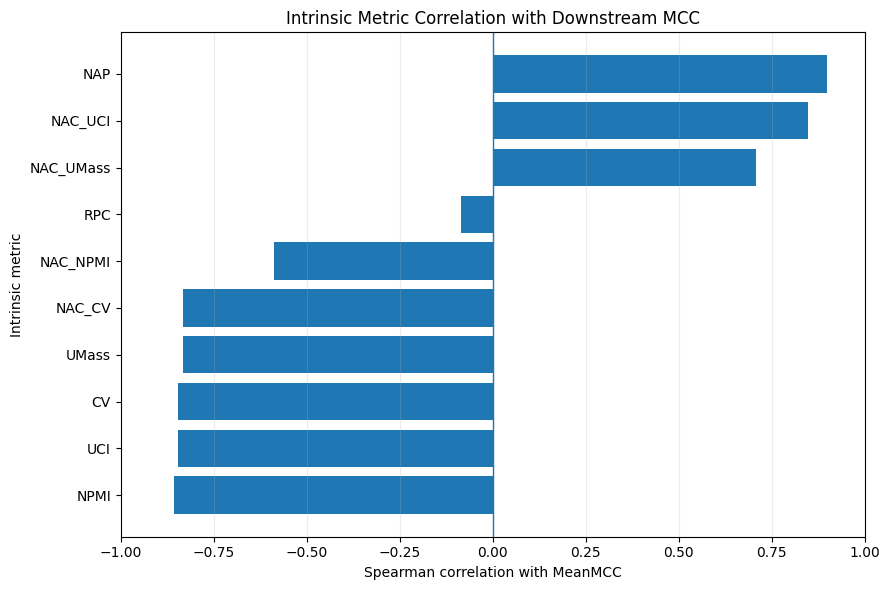

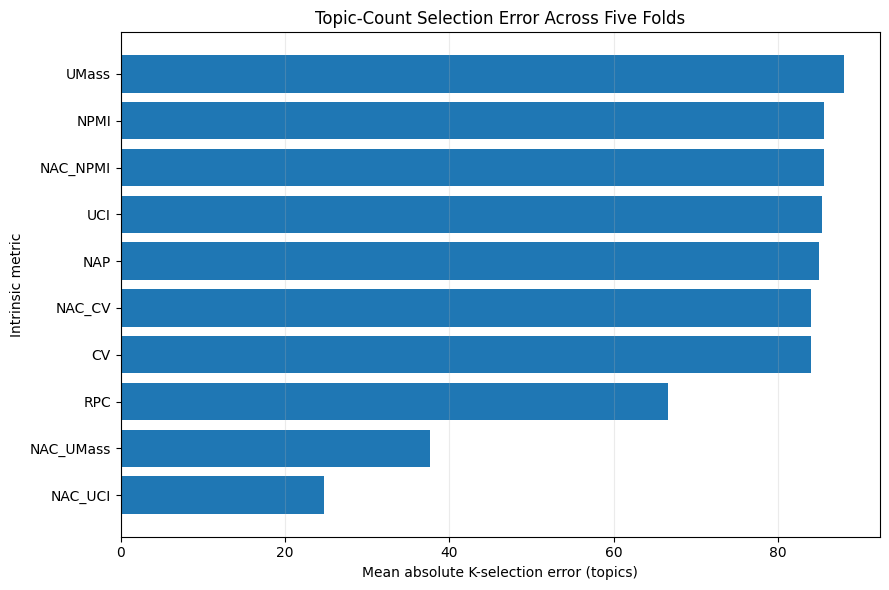

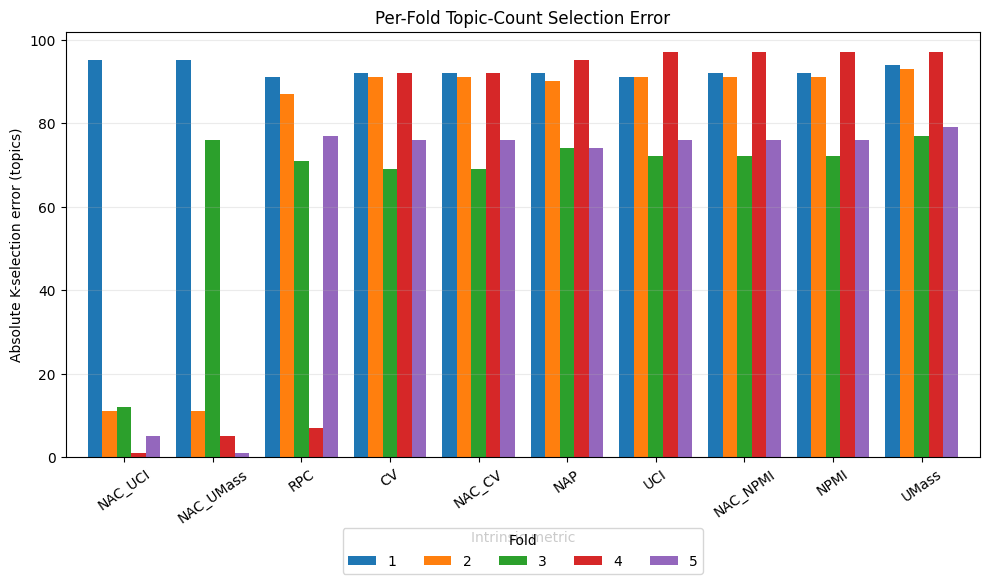


Generated publication-ready figures:
ng06_mean_absolute_k_error.pdf: 15,272 bytes
ng06_mean_absolute_k_error.png: 107,531 bytes
ng06_per_fold_k_error.pdf: 17,548 bytes
ng06_per_fold_k_error.png: 158,867 bytes
ng06_spearman_correlations.pdf: 13,487 bytes
ng06_spearman_correlations.png: 111,581 bytes

NG06-8 COMPLETE
✓ Spearman correlation figure saved
✓ Mean absolute K-error figure saved
✓ Per-fold K-error figure saved
✓ PNG (300 DPI) and PDF versions saved


In [ ]:

# ============================================================
# NG06-8 — PUBLICATION-READY DIAGNOSTIC PLOTS
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

ANALYSIS_DIR = BASE_DIR / "cross_metric_analysis"
FIGURE_DIR = ANALYSIS_DIR / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 1. Load persisted analysis results
# ------------------------------------------------------------
correlations = pd.read_csv(
    ANALYSIS_DIR / "ng06_metric_downstream_correlations.csv"
)

agreement = pd.read_csv(
    ANALYSIS_DIR / "ng06_per_fold_k_agreement.csv"
)

summary = pd.read_csv(
    ANALYSIS_DIR / "ng06_k_agreement_summary.csv"
)

required_corr = {"Metric", "SpearmanRho"}
required_error = {"Fold", "Metric", "AbsoluteKError"}

if not required_corr.issubset(correlations.columns):
    raise ValueError("Correlation file is missing required columns.")

if not required_error.issubset(agreement.columns):
    raise ValueError("Per-fold agreement file is missing required columns.")

if correlations["Metric"].duplicated().any():
    raise ValueError("Duplicate metric names in correlation file.")

# Use a consistent metric order based on mean absolute K error
metric_order = (
    summary.sort_values("MeanAbsoluteKError")["Metric"].tolist()
)

correlations = correlations[
    correlations["Metric"].isin(metric_order)
].copy()

correlations["Metric"] = pd.Categorical(
    correlations["Metric"],
    categories=metric_order,
    ordered=True
)
correlations = correlations.sort_values("Metric")

agreement = agreement[
    agreement["Metric"].isin(metric_order)
].copy()

# ------------------------------------------------------------
# 2. Plot Spearman correlations
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 6))

plot_corr = correlations.sort_values(
    "SpearmanRho", ascending=True
)

ax.barh(
    plot_corr["Metric"].astype(str),
    plot_corr["SpearmanRho"]
)
ax.axvline(0, linewidth=1)
ax.set_xlabel("Spearman correlation with MeanMCC")
ax.set_ylabel("Intrinsic metric")
ax.set_title(
    "Intrinsic Metric Correlation with Downstream MCC"
)
ax.set_xlim(-1, 1)
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()

fig.savefig(
    FIGURE_DIR / "ng06_spearman_correlations.png",
    dpi=300, bbox_inches="tight"
)
fig.savefig(
    FIGURE_DIR / "ng06_spearman_correlations.pdf",
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 3. Plot mean absolute K-selection error
# ------------------------------------------------------------
error_summary = summary.sort_values(
    "MeanAbsoluteKError", ascending=True
)

fig, ax = plt.subplots(figsize=(9, 6))

ax.barh(
    error_summary["Metric"].astype(str),
    error_summary["MeanAbsoluteKError"]
)
ax.set_xlabel("Mean absolute K-selection error (topics)")
ax.set_ylabel("Intrinsic metric")
ax.set_title(
    "Topic-Count Selection Error Across Five Folds"
)
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()

fig.savefig(
    FIGURE_DIR / "ng06_mean_absolute_k_error.png",
    dpi=300, bbox_inches="tight"
)
fig.savefig(
    FIGURE_DIR / "ng06_mean_absolute_k_error.pdf",
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 4. Plot per-fold K-selection errors
# ------------------------------------------------------------
error_pivot = agreement.pivot(
    index="Metric",
    columns="Fold",
    values="AbsoluteKError"
).reindex(metric_order)

fig, ax = plt.subplots(figsize=(10, 6))

error_pivot.plot(
    kind="bar",
    ax=ax,
    width=0.82
)

ax.set_xlabel("Intrinsic metric")
ax.set_ylabel("Absolute K-selection error (topics)")
ax.set_title(
    "Per-Fold Topic-Count Selection Error"
)
ax.legend(
    title="Fold",
    ncol=5,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.15)
)
ax.grid(axis="y", alpha=0.25)
ax.tick_params(axis="x", rotation=35)
fig.tight_layout()

fig.savefig(
    FIGURE_DIR / "ng06_per_fold_k_error.png",
    dpi=300, bbox_inches="tight"
)
fig.savefig(
    FIGURE_DIR / "ng06_per_fold_k_error.pdf",
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 5. Report generated artifacts
# ------------------------------------------------------------
print("\nGenerated publication-ready figures:")
for path in sorted(FIGURE_DIR.glob("ng06_*")):
    print(f"{path.name}: {path.stat().st_size:,} bytes")

print("\n" + "=" * 80)
print("NG06-8 COMPLETE")
print("✓ Spearman correlation figure saved")
print("✓ Mean absolute K-error figure saved")
print("✓ Per-fold K-error figure saved")
print("✓ PNG (300 DPI) and PDF versions saved")
print("=" * 80)
